In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 5/7/2022
# version ='1.0'

### Demo: A minimization on a non-quadratic problem in $R^2$

In the text book "book-convex-2004", section 9.3.2, a minimization on a non-quadratic objective function in $R^2$,
$$
f(x) = e^{x_1+3x_2-0.1}+e^{x_1-3x_2-0.1}+e^{-x_1-0.1}
$$

In this demo using the the python implementation for the gradient descent method with the backtracking line search, the following demo shows the iterations during the convergence, starting from the point $(-2, 2)$. 


In the above figures, both the exact line search and the backtracking line search are implemented. In the exact line search method, the \textit{scipy.optimize.minimize} with the method = 'TNC' is used to solve the problem
$$
t = \displaystyle{arg\min_{s\geq 0}}f(x+s\Delta x)
$$

where the starting point in the above minimization problem is $s^{(0)}=\frac{1}{|\Delta x|}$, in order to avoid math overflow in the calculation of exponentials.

More details on the setup of the demo in Jupiter notebook for practice can be accessed from the Lecture's JupyterLab webpage:

[JupyterLab webpage](https://wuzhuchun.club:9091/lab/tree/welcome.ipynb}{https://wuzhuchun.club:9091/lab/tree/welcome.ipynb)






In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
from scipy.optimize import minimize
from numpy import linalg as LA

$$ f(x) = e^{x_1+3x_2-0.1}+e^{x_1-3x_2-0.1}+e^{-x_1-0.1} $$

In [2]:
def my_f(x):
    """
    $$ f(x) = e^{x_1+3x_2-0.1}+e^{x_1-3x_2-0.1}+e^{-x_1-0.1} $$
    :param x:
    :return:
    """
    x1 = x[0]
    x2 = x[1]
    return math.exp(x1 + 3 * x2 - 0.1) + math.exp(x1 - 3 * x2 - 0.1) + math.exp(-x1 - 0.1)


def my_derivative_f(x):
    """
    $\nabla f(x)$
    :param x:
    :return:
    """
    x1 = x[0]
    x2 = x[1]
    derivative_1 = 1 * math.exp(x1 + 3 * x2 - 0.1) + 1 * math.exp(x1 - 3 * x2 - 0.1) - math.exp(-x1 - 0.1)
    derivative_2 = 3 * math.exp(x1 + 3 * x2 - 0.1) - 3 * math.exp(x1 - 3 * x2 - 0.1)
    return np.array([derivative_1, derivative_2])

backtracking line search

In [7]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta):
    """
    backtracking line search
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :return:
    """
    t = 1
    while f(x + delta_x * t) > f(x) + alpha * t * np.dot(df(x), delta_x):
        t = beta * t
    return t

In the exact line search method, the 'scipy.optimize.minimize' with the method = 'TNC' is used to solve the minimization problem

In [6]:
def exact_line_search(f, x, dx):
    """
    In the exact line search method, the 'scipy.optimize.minimize' with the method = 'TNC' is used to solve the minimization problem
    :param f:
    :param x:
    :param dx:
    :return:
    """
    def exact_line_search_min_f(s, f, x, dx):
        return f(x + s * dx)

    s0 = 1 / LA.norm(dx)
    res = minimize(exact_line_search_min_f, s0, args=(f, x, dx), bounds=[(0, None)], method='TNC')
    return res.x

plot the convergence of $x$ during the minimization on a non-quadratic objective function,
separately for exact line search and backtracking line search

In [8]:
def plot_non_quadratic_convergence():
    """
    plot the convergence of $x$ during the minimization on a non-quadratic objective function,
    separately for exact line search and backtracking line search
    :return:
    """
    min_x1 = -3
    max_x1 = 3
    min_x2 = -3
    max_x2 = 3
    delta = 0.1
    x = np.arange(min_x1, max_x1, delta)
    y = np.arange(min_x2, max_x2, delta)
    X, Y = np.meshgrid(x, y)
    Z = np.zeros(X.shape)

    for x1_i in range(len(x)):
        for x2_i in range(len(y)):
            x1 = x[x1_i]
            x2 = y[x2_i]
            Z[x2_i][x1_i] = my_f(np.array([x1, x2]))

    ax1 = plt.subplot(1, 2, 1)
    # levels = np.exp(np.arange(-2, 3, 0.1))
    levels = np.arange(0, 100, 0.1)
    CS = ax1.contour(X, Y, Z, linestyles='dashed', levels=levels, vmin=0, vmax=10)
    ax1.clabel(CS, fontsize=6, inline=True)
    ax1.set_xlabel(r'$x_1$')
    ax1.set_ylabel(r'$x_2$')
    ax1.set_title(r'$f(x)$')

    # using exact line search method
    alpha = 0.1
    beta = 0.7
    x0 = np.array([-2, 2])
    num_iter = 20
    x = x0
    delta_x = -1 * my_derivative_f(x0)
    x_points_1 = np.zeros([num_iter, 2])
    fx_1 = np.zeros([num_iter, 1])
    for iter in range(num_iter):
        x_points_1[iter] = x
        fx_1[iter] = my_f(x)
        t = exact_line_search(my_f, x, delta_x)
        x_next = x + t * delta_x

        x = x_next
        delta_x = -1 * my_derivative_f(x_next)

    ax1.plot(x_points_1[:, 0], x_points_1[:, 1], color='C1', marker='+', label='exact-line')

    # using backtracking line search method
    x0 = np.array([-2, 2])
    num_iter = 20
    x = x0
    delta_x = -1 * my_derivative_f(x0)
    x_points_2 = np.zeros([num_iter, 2])
    fx_2 = np.zeros([num_iter, 1])
    for iter in range(num_iter):
        x_points_2[iter] = x
        fx_2[iter] = my_f(x)
        t = backtracking_line_search(my_f, my_derivative_f, x, delta_x, alpha, beta)
        x_next = x + t * delta_x

        x = x_next
        delta_x = -1 * my_derivative_f(x_next)

    ax1.plot(x_points_2[:, 0], x_points_2[:, 1], color='C2', marker='x', label='backtracking')
    ax1.legend()

    ax2 = plt.subplot(1, 2, 2)

    ax2.semilogy(np.arange(0, num_iter), fx_1 - fx_1[num_iter - 1], marker='+', fillstyle='none', label='exact-line')
    ax2.semilogy(np.arange(0, num_iter), fx_2 - fx_2[num_iter - 1], marker='o', fillstyle='none', label='backtracking')
    ax2.xaxis.set_major_formatter(FormatStrFormatter('%d'))
    ax2.set_xlabel('k')
    ax2.set_ylabel(r'$f(x^k)-p^*$')
    ax2.grid()
    ax2.legend()
    plt.show()

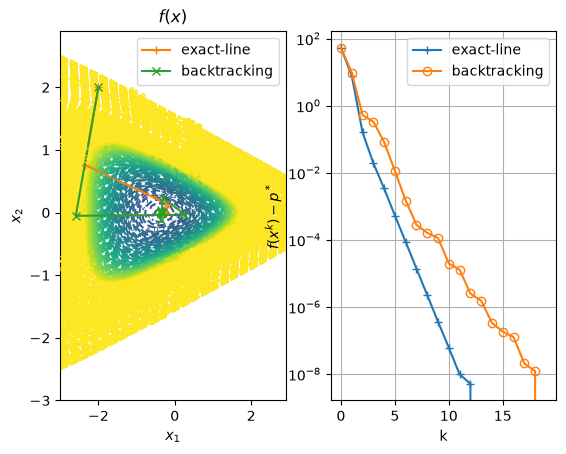

In [9]:
if __name__ == "__main__":
    plot_non_quadratic_convergence()